In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: []


In [2]:
TRAIN_PATH = "../data/processed/splits/train.csv"
VAL_PATH = "../data/processed/splits/validation.csv"
TEST_PATH = "../data/processed/splits/test.csv"

train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)


Training: (2525, 9)
Validation: (490, 9)
Testing: (462, 9)


In [3]:
CLASS_NAMES = [
    "Black rot",
    "esca",
    "healthy",
    "leaf blight"
]

class_to_index = {
    class_name: index
    for index, class_name in enumerate(CLASS_NAMES)
}

index_to_class = {
    index: class_name
    for class_name, index in class_to_index.items()
}

print(class_to_index)

{'Black rot': 0, 'esca': 1, 'healthy': 2, 'leaf blight': 3}


In [4]:
IMG_SIZE = (224, 224)

def load_image(image_path):
    image = tf.io.read_file(image_path)

    image = tf.image.decode_jpeg(
        image,
        channels=3
    )

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = image / 255.0

    return image

In [5]:
def create_dataset(dataframe, batch_size=32):

    image_paths = dataframe["image_path"].values

    labels = dataframe["label"].map(
        class_to_index
    ).values

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    dataset = dataset.map(
        lambda path, label: (
            load_image(path),
            label
        ),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(batch_size)

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset

In [6]:
BATCH_SIZE = 32

train_ds = create_dataset(
    train_df,
    BATCH_SIZE
)

val_ds = create_dataset(
    val_df,
    BATCH_SIZE
)

test_ds = create_dataset(
    test_df,
    BATCH_SIZE
)

print("Datasets created successfully!")

Datasets created successfully!


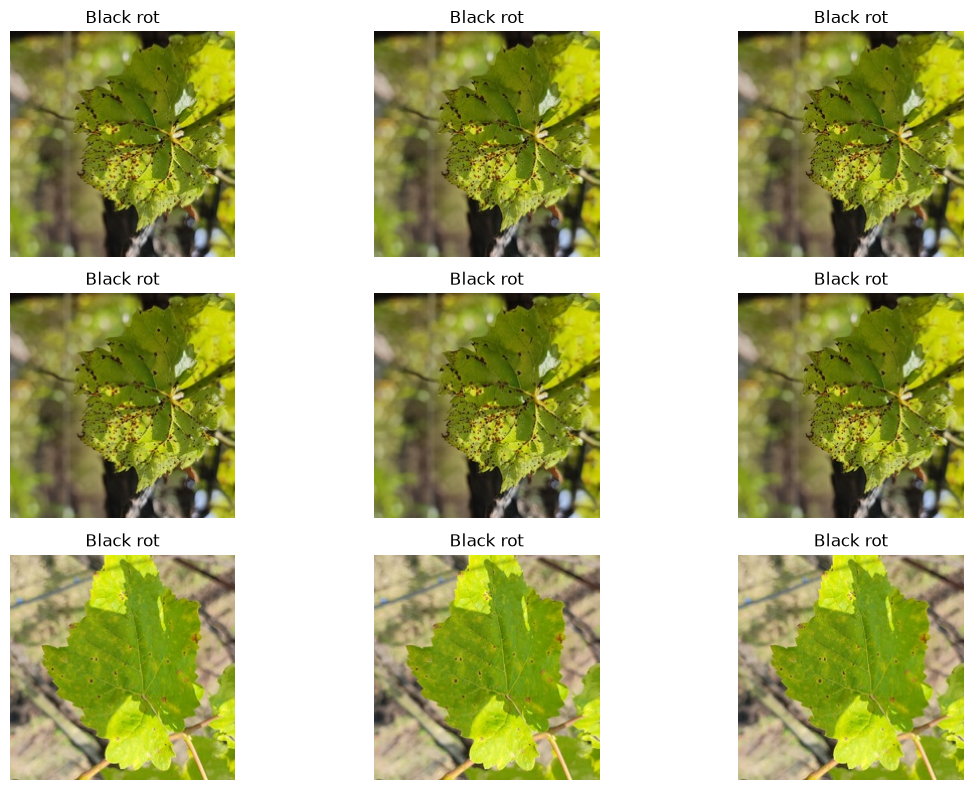

In [7]:
images, labels = next(iter(train_ds))

plt.figure(figsize=(12, 8))

for i in range(9):

    plt.subplot(3, 3, i + 1)

    plt.imshow(images[i])

    plt.title(
        index_to_class[int(labels[i])]
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
model = keras.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(4, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,476 (42.61 MB)

 Trainable params: 11,169,476 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [12]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        filepath="../models/baseline_cnn_best.keras",
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.00001,
        verbose=1
    )
]

In [13]:
import os

os.makedirs("../models", exist_ok=True)

print("Models directory ready!")

Models directory ready!


In [14]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)

Epoch 1/20


c:\Users\shewa\anaconda3\envs\terraspectra\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 495ms/step - accuracy: 0.7291 - loss: 6.5729
Epoch 1: val_accuracy improved from None to 0.30000, saving model to ../models/baseline_cnn_best.keras

Epoch 1: finished saving model to ../models/baseline_cnn_best.keras
79/79 ━━━━━━━━━━━━━━━━━━━━ 44s 532ms/step - accuracy: 0.7291 - loss: 6.5729 - val_accuracy: 0.3000 - val_loss: 14.5294 - learning_rate: 0.0010
Epoch 2/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 564ms/step - accuracy: 0.3640 - loss: 2.2219
Epoch 2: val_accuracy did not improve from 0.30000
79/79 ━━━━━━━━━━━━━━━━━━━━ 46s 584ms/step - accuracy: 0.3640 - loss: 2.2219 - val_accuracy: 0.3000 - val_loss: 8.4933 - learning_rate: 0.0010
Epoch 3/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 513ms/step - accuracy: 0.1374 - loss: 1.7905
Epoch 3: val_accuracy did not improve from 0.30000
79/79 ━━━━━━━━━━━━━━━━━━━━ 42s 536ms/step - accuracy: 0.1374 - loss: 1.7905 - val_accuracy: 0.2163 - val_loss: 1.3894 - learning_rate: 0.0010
Epoch 4/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 538ms/step 

In [15]:
def create_dataset(dataframe, batch_size=32, shuffle=False):
    image_paths = dataframe["image_path"].values
    labels = dataframe["label"].map(class_to_index).values

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        lambda path, label: (load_image(path), label),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

In [16]:
train_ds = create_dataset(train_df, batch_size=32, shuffle=True)
val_ds = create_dataset(val_df, batch_size=32, shuffle=False)
test_ds = create_dataset(test_df, batch_size=32, shuffle=False)

In [17]:
print("Training class distribution:")
print(train_df["label"].value_counts())

print("\nValidation class distribution:")
print(val_df["label"].value_counts())

print("\nTesting class distribution:")
print(test_df["label"].value_counts())

Training class distribution:
label
healthy        815
esca           646
Black rot      581
leaf blight    483
Name: count, dtype: int64

Validation class distribution:
label
healthy        147
Black rot      124
esca           113
leaf blight    106
Name: count, dtype: int64

Testing class distribution:
label
healthy        147
esca           129
Black rot      103
leaf blight     83
Name: count, dtype: int64


In [18]:
model_v2 = keras.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(256, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(4, activation="softmax")
])

model_v2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,748 (1.62 MB)

 Trainable params: 422,788 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [19]:
model_v2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [20]:
callbacks_v2 = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        filepath="../models/baseline_cnn_v2_best.keras",
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.000001,
        verbose=1
    )
]

In [21]:
history_v2 = model_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks_v2
)

Epoch 1/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6891 - loss: 0.7782
Epoch 1: val_accuracy improved from None to 0.21633, saving model to ../models/baseline_cnn_v2_best.keras

Epoch 1: finished saving model to ../models/baseline_cnn_v2_best.keras
79/79 ━━━━━━━━━━━━━━━━━━━━ 110s 1s/step - accuracy: 0.6891 - loss: 0.7782 - val_accuracy: 0.2163 - val_loss: 1.5273 - learning_rate: 1.0000e-04
Epoch 2/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7600 - loss: 0.5544
Epoch 2: val_accuracy improved from 0.21633 to 0.25306, saving model to ../models/baseline_cnn_v2_best.keras

Epoch 2: finished saving model to ../models/baseline_cnn_v2_best.keras
79/79 ━━━━━━━━━━━━━━━━━━━━ 108s 1s/step - accuracy: 0.7600 - loss: 0.5544 - val_accuracy: 0.2531 - val_loss: 2.1252 - learning_rate: 1.0000e-04
Epoch 3/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8016 - loss: 0.4797
Epoch 3: val_accuracy did not improve from 0.25306
79/79 ━━━━━━━━━━━━━━━━━━━━ 114s 1s/step - accuracy: 0

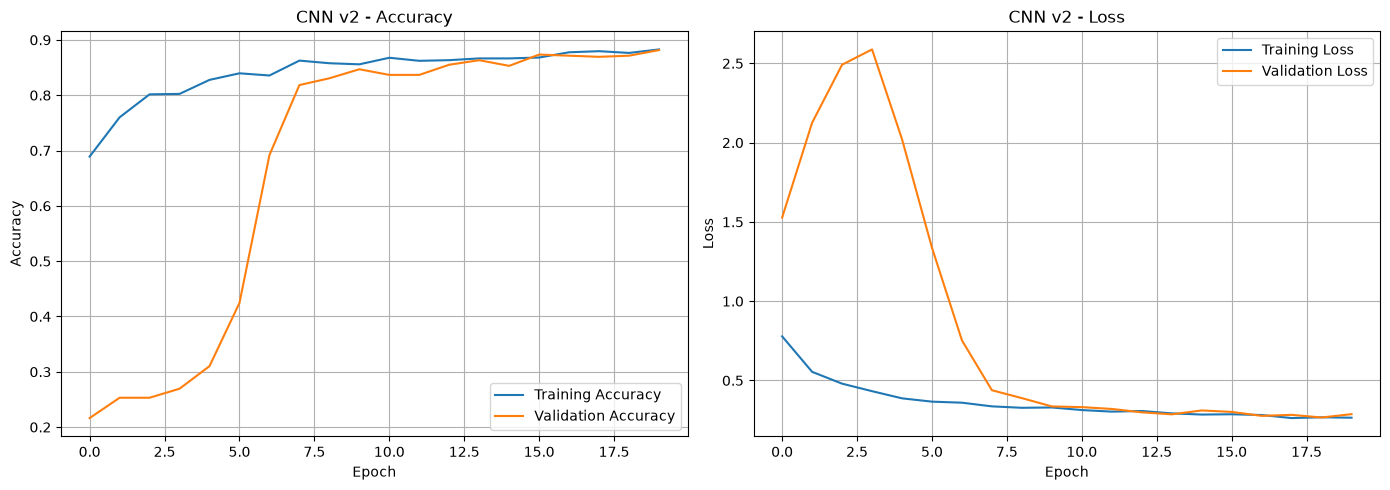

In [23]:
plt.figure(figsize=(14, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history_v2.history["accuracy"], label="Training Accuracy")
plt.plot(history_v2.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN v2 - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history_v2.history["loss"], label="Training Loss")
plt.plot(history_v2.history["val_loss"], label="Validation Loss")
plt.title("CNN v2 - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [24]:
test_loss, test_accuracy = model_v2.evaluate(test_ds)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy Percentage: {test_accuracy * 100:.2f}%")

15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 196ms/step - accuracy: 0.8853 - loss: 0.2328
Test Loss: 0.2328
Test Accuracy: 0.8853
Test Accuracy Percentage: 88.53%


In [25]:
from sklearn.metrics import classification_report
import numpy as np

# Generate predictions
y_pred_prob = model_v2.predict(test_ds)

# Convert probabilities to predicted class
y_pred = np.argmax(y_pred_prob, axis=1)

# Actual labels
y_true = test_df["label"].map(class_to_index).values

# Classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=CLASS_NAMES,
    digits=4
))

15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 243ms/step
              precision    recall  f1-score   support

   Black rot     0.9714    0.9903    0.9808       103
        esca     0.8015    0.8140    0.8077       129
     healthy     0.9932    1.0000    0.9966       147
 leaf blight     0.7051    0.6627    0.6832        83

    accuracy                         0.8853       462
   macro avg     0.8678    0.8667    0.8671       462
weighted avg     0.8831    0.8853    0.8840       462



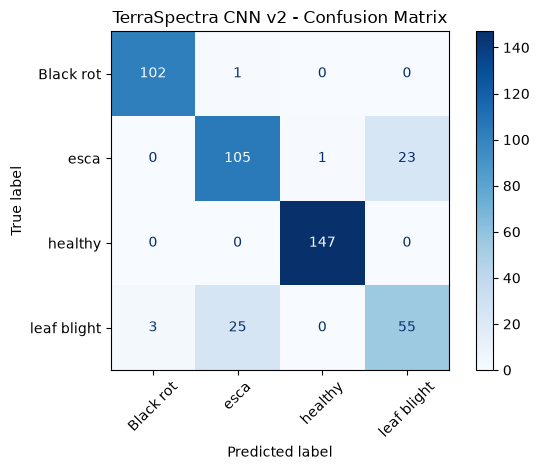

In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

disp.plot(
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

plt.title("TerraSpectra CNN v2 - Confusion Matrix")
plt.tight_layout()
plt.show()